# Figure 2: T-S Space Summary

## Import Packages

In [1]:
import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import datetime
import math

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Import Data

In [2]:
# ---------- OBSERVATIONAL DATA ----------
ROOT = '/g/data/gv90/ad6790/amery-amisor'
os.chdir(f'{ROOT}/notebooks')

from fun_filtering import lowpass_filter

df = pd.read_parquet(f'{ROOT}/data/proc/04_filtered.parquet')

# ---------- NEUTRAL DENSITY CURVES ----------
# Load in the neutral density contours as determined by Blanckensee et al. (2024)
with open("/g/data/gv90/ad6790/amery-amisor/data/external/SiennaNeve-CDObs-203a48c/Notebooks/neu_dens_contours.pkl", "rb") as f: 
    nd_contours = pickle.load(f)
x_curve1 = nd_contours["x_curve1"]  # 28.27 contour
y_curve1 = nd_contours["y_curve1"]
x_curve2 = nd_contours["x_curve2"]  # 28.00 contour
y_curve2 = nd_contours["y_curve2"]

## Define Resuable Functions

In [3]:
# Define a function to label the neutral density curves tangentially
def label_curve_tangent(ax, x_curve, y_curve, fraction, text, color, fontsize, **kwargs):
    n = len(x_curve)
    # Define an index for the anchor point based on the length of the curve and the fractional distance along it
    idx = int(fraction * (n - 1))
    # Define the anchor point
    anchor_point = (x_curve[idx], y_curve[idx])

    # Pick points neighbouring the anchoring point to estimate the tangent
    i0 = max(idx - 1, 0)
    i1 = min(idx + 1, n - 1)

    # Convert these points to display coordinates so the angle accounts of the axis scaling
    p0 = ax.transData.transform((x_curve[i0], y_curve[i0]))
    p1 = ax.transData.transform((x_curve[i1], y_curve[i1]))
    # Calculate the change in display in display coordinates in the x and y directions
    dx_display = p1[0] - p0[0] 
    dy_display = p1[1] - p0[1] 

    # Calculate the angle of the slope 
    angle = np.degrees(np.arctan2(dy_display, dx_display))
    
    # Find a perpendicular unit vector in display coordinates to create a buffer between the curve and the label 
    length = np.hypot(dx_display, dy_display)
    perp_x = -dy_display / length
    perp_y = dx_display / length

    # Find the anchor point and the offset point from here in display coordinates
    anchor_display = ax.transData.transform(anchor_point)
    offset_display = (anchor_display[0] + 10 * perp_x, anchor_display[1] + 10 * perp_y)

    # Convert this offset point back into data coordinates to be able to plot it correctly
    offset_point = ax.transData.inverted().transform(offset_display)

    # Check if the anchor point falls within the plot's visible area and if it doesn't we ignore this label
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    if not (xlim[0] <= anchor_point[0] <= xlim[1] and ylim[0] <= anchor_point[1] <= ylim[1]):
        return 

    ax.text(offset_point[0], offset_point[1], text, rotation=angle, rotation_mode="anchor", ha="center", va="center", color=color, fontsize=fontsize, **kwargs)

def _doy_month_ticks(doy_min, doy_max):
    """Return (tick_positions, tick_labels) for month starts within [doy_min, doy_max]."""
    ref = 2001  # non-leap reference year
    ticks, labels = [], []
    for m in range(1, 13):
        ts = pd.Timestamp(ref, m, 1)
        doy = ts.timetuple().tm_yday
        # In year-specific austral plots, December is shifted to negative DOY
        if doy_min < 0 and m == 12:
            doy -= 365
        if doy_min <= doy <= doy_max:
            ticks.append(doy)
            labels.append(ts.strftime("%b"))
    return ticks, labels

# trim a T-S curve so it starts on the 0 dbar freezing line rather than running below it
def clip_to_freezing(x, y):
    """Keep only the part of a T-S curve at or above the surface freezing point."""
    d = y - gsw.CT_freezing(x, 0, 0)
    keep = d >= 0
    if not keep.any():
        return x[keep], y[keep]
    i = np.argmax(keep)                       # first point above freezing
    if i == 0:
        return x[keep], y[keep]
    # Linear interpolation between the last point below and the first above, so the
    # curve begins exactly on the freezing line instead of jumping to the next sample
    f = -d[i-1] / (d[i] - d[i-1])
    x0 = x[i-1] + f * (x[i] - x[i-1])
    y0 = y[i-1] + f * (y[i] - y[i-1])
    return np.concatenate([[x0], x[keep]]), np.concatenate([[y0], y[keep]])


def truncate_cmap(cmap_name, lo=0.0, hi=1.0, n=256):
    """Keep only the lo-to-hi portion of a colormap (fractions of the full range)."""
    base = plt.get_cmap(cmap_name, n)
    return mcolors.ListedColormap(base(np.linspace(lo, hi, n)), name=f"{cmap_name}_trunc")

# Colormap for the DOY gradient plot — cyclic, maps naturally to a year
def roll_cyclic_cmap(cmap_name, shift, n=256):
    """Rotate a cyclic colormap by `shift` (fraction of a full cycle)."""
    base = plt.get_cmap(cmap_name, n)
    cols = base(np.linspace(0, 1, n))
    return mcolors.ListedColormap(np.roll(cols, int(round(shift * n)), axis=0), name=f"{cmap_name}_rolled")

## Define Constant and Common Variables

In [39]:
# Font sizes for this figure
FS_MAIN = 14      # axis labels, colourbar labels, water-mass labels
FS_SMALL = 12     # tick labels, legend, curve and contour labels

# Defaults for anything without its own fontsize (ticks, colourbar ticks, legend)
plt.rcParams.update({
    "font.size": FS_MAIN,
    "axes.titlesize": FS_MAIN,
    "axes.labelsize": FS_MAIN,
    "xtick.labelsize": FS_SMALL,
    "ytick.labelsize": FS_SMALL,
    "legend.fontsize": FS_SMALL,
})

In [58]:
# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
AVG_PRESSURES = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 661.4,    "4054": 872.2,   "3883": 1227.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

# Colours assigned to boreholes in month mode (when multiple boreholes are shown)
BOREHOLE_COLOURS = {
    "AM01": {"1969": "darkgreen", "1970": "forestgreen", "1971": "lightgreen"},
    "AM02": {"1623": "darkred", "1624": "red", "1174": "lightcoral"},
    "AM03": {"4055": "saddlebrown", "4054": "sandybrown", "3883": "peachpuff"},
    "AM04": {"1972": "black", "1973": "grey", "1974": "lightgrey"},
    "AM05": {"7327": "indigo", "7326": "darkviolet", "7322": "violet"},
    "AM06": {"7325": "navy", "7324": "royalblue", "7323": "lightskyblue"}
}

# Define a colourmap for the days-of-year
DOY_CMAP = roll_cyclic_cmap("twilight_shifted", 0.25)

# Initialise a list of salinity values corresponding to the source water mass at ~-1.9C
meltwater_mixing_lines = [34.5]

obsv_kw = dict(s=2)
freeze_kw = dict(color="blue", linestyle="-", lw=0.8, label="_", zorder=4)
isopycnal_kw = dict(colors="black", linestyles="-", linewidths=0.6, alpha=0.2, zorder=1)
neutral_kw = dict(color="r", linestyle="-", lw=1.5, zorder=4)
gade_kw = dict(color="k", linestyle="--", lw=1.5, label="_", zorder=5)
label_kw = dict(fontsize=FS_MAIN)
grid_labels=FS_SMALL
legend_kw = dict(ncol=2, fontsize=FS_SMALL, frameon=False, markerscale=2, fancybox=False)

## Figure SI
### Settings

In [59]:
# AM02 upper MicroCAT
BOREHOLE, CAT = "AM02", "1623"
# Years to plot, one panel each - 2002 falls in the gap in this record
YEARS = [2001, 2003, 2004, 2005, 2006]
 
# Axis limits shared by every panel
xlim_sal = (34.301, 34.699)
ylim_temp = (-2.199, -1.701)
 
# Day-of-year colour scale fixed to the whole year, so the same colour means the same date on every panel
doy_norm_yr = mcolors.Normalize(vmin=1, vmax=366)

### Organise Data

In [60]:
# Every observation from this MicroCAT, in time order
data = df[(df["borehole"] == BOREHOLE) & (df["cat"] == CAT)].sort_values("time").copy()

# Fractional day of year, so the half-hourly points within a day spread smoothly through the colour scale
data["doy"] = data["time"].dt.dayofyear + data["time"].dt.hour / 24 + data["time"].dt.minute / 1440

### PLOT

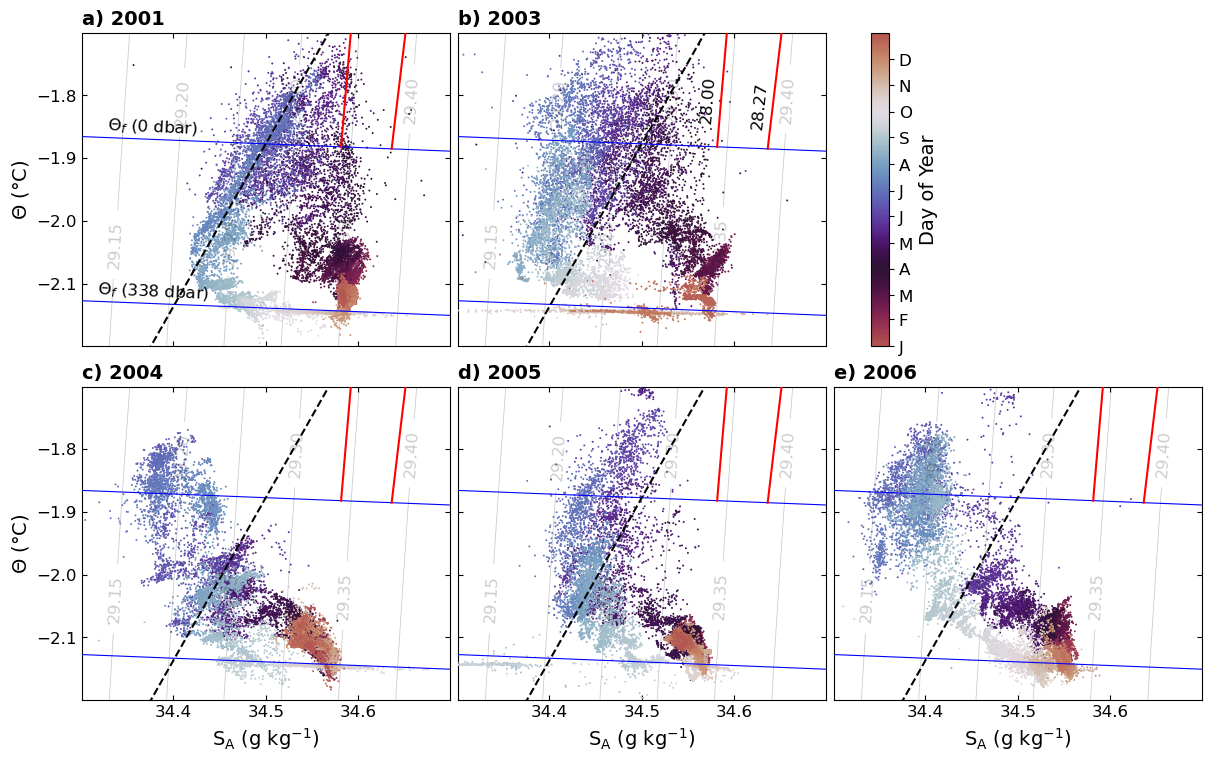

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True, layout='constrained')

year_axes = [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1], axes[1, 2]]

salinity_range = np.linspace(*xlim_sal, 100)
temp_range = np.linspace(*ylim_temp, 100)

# Iterate over each recorded year
for i, year in enumerate(YEARS):
    ax = year_axes[i]
    ax.set_xlim(*xlim_sal)
    ax.set_ylim(*ylim_temp)

    # -- OBSERVATIONS FOR THIS YEAR --
    year_data = data[data["time"].dt.year == year]

    ax.scatter(year_data["absolute_salinity"], year_data["conservative_temperature"], c=year_data["doy"], cmap=DOY_CMAP, norm=doy_norm_yr, s=2, edgecolors='none', zorder=3, rasterized=True)

    # -- OVERLAYS --
    # - Freezing point temperature line at 0 dbar (saturation fraction = 0) -
    CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
    ax.plot(salinity_range, CT_freeze_0, **freeze_kw)
    if year == 2001:
        label_curve_tangent(ax, salinity_range, CT_freeze_0, 0.2, r"$\Theta_f$ (0 dbar)", "black", grid_labels, zorder=3)

    # - Freezing point temperature line at the average mooring pressure (determined at deployment) -
    CT_freeze_p = gsw.CT_freezing(salinity_range, AVG_PRESSURES[CAT], 0)
    ax.plot(salinity_range, CT_freeze_p, **freeze_kw)
    if year == 2001:
        label_curve_tangent(ax, salinity_range, CT_freeze_p, 0.2, fr"$\Theta_f$ ({AVG_PRESSURES[CAT]:.0f} dbar)", "black", grid_labels, zorder=3)

    # - Isopycnals (potential density anomaly contours) referenced to the average pressure of the MicroCAT -
    salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
    sigma = gsw.rho(salinity_grid, temp_grid, AVG_PRESSURES[CAT]) - 1000
    cs = ax.contour(salinity_grid, temp_grid, sigma, **isopycnal_kw)
    ax.clabel(cs, inline=True, fontsize=grid_labels, fmt="%.2f")

    # - Neutral density curves from Blanckensee et al. (2024) -
    xc1, yc1 = clip_to_freezing(np.asarray(x_curve1), np.asarray(y_curve1))
    xc2, yc2 = clip_to_freezing(np.asarray(x_curve2), np.asarray(y_curve2))
    ax.plot(xc1, yc1, **neutral_kw)
    ax.plot(xc2, yc2, **neutral_kw)
    if year == 2003:
        label_curve_tangent(ax, xc2, yc2, 0.03, "28.00", "black", grid_labels)
        label_curve_tangent(ax, xc1, yc1, 0.03, "28.27", "black", grid_labels)

    # - Meltwater mixing lines -
    # Meltwater mixing line using gsw (equation 16 from McDougall et al. (2014))
    # First, assume "the temperature of the glacial ice, -15 C, measured from a thermistor cable at AM01" as per Herraiz-Borreguero et al. (2013) (also used in Silvano et al. (2017))
    t_ice = -15.0

    # REVIEW - WHAT PRESSURE DO WE WANT TO PUT HERE?? (note: slope is not particularly sensitive to this pressure)
    pressure_source = 200

    for salinity_source in meltwater_mixing_lines:
        # Here, we will define the temp of the source water mass as the surface (0 dbar) freezing point temperature at the given source salinities we have chosen
        temp_source = float(gsw.CT_freezing(salinity_source, 0, 0))
        dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, pressure_source, t_ice)
        slope = 1 / dSA_dCT  # dCT/dSA
        CT_gade = temp_source + slope * (salinity_range - salinity_source)
        ax.plot(salinity_range, CT_gade, **gade_kw)

    ax.set_title(f"{chr(97 + i)}) {year}", loc='left', fontweight='bold')
    ax.xaxis.set_major_locator(mticker.MultipleLocator(0.1))
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)

for r in range(2):
    axes[r, 0].set_ylabel(r"$\Theta$ (°C)", **label_kw)

for ax in axes[1, :]:
    ax.set_xlabel(r"$\mathrm{S_{A} \ (g \ kg^{-1})}$", **label_kw)
axes[0, 2].tick_params(axis="x", labelbottom=True)

# ---------- DOY COLOURBAR ----------
# The empty sixth slot holds a horizontal colourbar, rather than squeezing one down the side
axes[0, 2].axis("off")
# [left, bottom, width, height]
cax = axes[0, 2].inset_axes([0.1, 0.0, 0.05, 1.0])
# Draw the colourbar labelled with calender months
sm = cm.ScalarMappable(norm=doy_norm_yr, cmap=DOY_CMAP)
cbar = fig.colorbar(sm, cax=cax, orientation="vertical")
cbar.set_label("Day of Year", **label_kw)
# Month starts across the whole year, labelled with their first letter
ticks, tick_labels = _doy_month_ticks(1, 365)
cbar.set_ticks(ticks)
cbar.set_ticklabels([label[0] for label in tick_labels])

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsT-S_AM02Upper.jpg', format='jpg', dpi=300, bbox_inches='tight')
plt.show()